In [1]:
from pynwb import NWBHDF5IO
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [2]:
file_path = r"C:\Users\kianb\Projects\mouse-v1-research\data\session_757216464\session_757216464.nwb"
io=NWBHDF5IO(file_path, mode="r")
nwbfile = io.read()
#print(nwbfile.session_id)
#print(nwbfile.session_description)
#print(nwbfile.session_start_time)
#print(nwbfile.institution)

#print("Total units:", len(nwbfile.units))

print("Unit columns:", nwbfile.units.colnames)
units_df = nwbfile.units.to_dataframe()
#print(units_df.head())


channels = pd.read_csv("../data/channels.csv")

Unit columns: ('waveform_halfwidth', 'waveform_duration', 'silhouette_score', 'nn_hit_rate', 'amplitude_cutoff', 'quality', 'spread', 'isi_violations', 'presence_ratio', 'peak_channel_id', 'nn_miss_rate', 'isolation_distance', 'PT_ratio', 'local_index', 'snr', 'velocity_below', 'd_prime', 'firing_rate', 'velocity_above', 'max_drift', 'cumulative_drift', 'repolarization_slope', 'amplitude', 'cluster_id', 'l_ratio', 'recovery_slope', 'spike_times', 'spike_amplitudes', 'waveform_mean')


In [3]:
#print(units_df['spike_times'])
merged_df = pd.merge(units_df, channels, left_on='peak_channel_id', right_on='id', how='left')
visp_units = merged_df[merged_df["ecephys_structure_acronym"] == "VISp"]

In [4]:
Quality_pass = visp_units[(visp_units['amplitude_cutoff'] < 0.1) & (visp_units['isi_violations'] < 0.5) & (visp_units['presence_ratio']>0.9) & (visp_units['quality'] == 'good')]
#print(Quality_pass['spike_times'],len(Quality_pass['spike_times']))

In [5]:
first_row=Quality_pass.iloc[0]
print(first_row['id'])
print(len(first_row['spike_times']))
print(first_row['spike_times'][0:10])

850116268.0
40146
[4.25091132 4.35541136 4.5429781  4.61111146 4.6187448  4.74894485
 4.83854489 4.85534489 4.96354494 5.02884496]


In [6]:
spikes_10s = first_row['spike_times'][first_row['spike_times'] < 10]
print(spikes_10s)

[4.25091132 4.35541136 4.5429781  4.61111146 4.6187448  4.74894485
 4.83854489 4.85534489 4.96354494 5.02884496 5.0427783  5.38961177
 5.55877851 5.76057859 5.96994534 7.04674577 7.3774459  7.634746
 7.94427946 8.10107952 8.16051288 8.19417956 8.32207961 8.3729463
 8.41447965 8.49614635 8.62357973 8.69144642 8.73921311 8.85264649
 8.95554653 9.0531799  9.81174687]


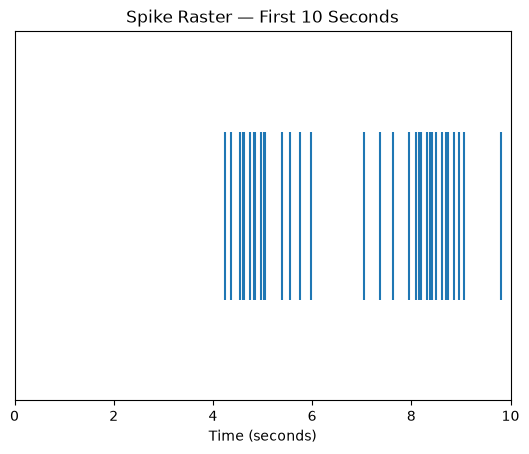

In [7]:
plt.eventplot(spikes_10s)
plt.title("Spike Raster — First 10 Seconds")
plt.xlabel("Time (seconds)")
plt.yticks([])
plt.xlim(0, 10)
plt.show()

In [8]:
r=len(spikes_10s)/10
print(r)
print(first_row['firing_rate'])


3.3
4.1694903974183


[3.3, 12.8, 9.2, 7.2, 8.8, 8.2, 8.8, 7.1, 4.9, 4.6]
[0, 10, 20, 30, 40, 50, 60, 70, 80, 90]


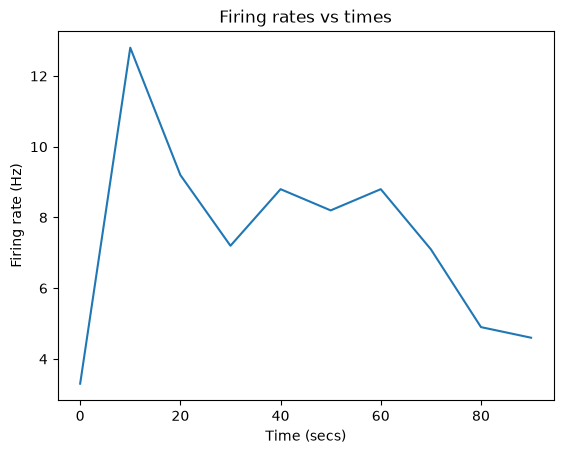

In [9]:
spike_avgs=[r]
Y=[0]
for i in range(1,10):
    spikes_next = first_row['spike_times'][(first_row['spike_times'] >= (i*10)) & (first_row['spike_times'] < ((i*10)+10))]
    spike_avgs.append((len(spikes_next))/10)
    Y.append(i*10)
print(spike_avgs)
print(Y)
plt.plot(Y,spike_avgs)
plt.title("Firing rates vs times")
plt.xlabel("Time (secs)")
plt.ylabel("Firing rate (Hz)")
plt.show()

In [10]:
plot_mean=np.mean(spike_avgs)
print(plot_mean)
plot_std = np.std(spike_avgs)
print(plot_std)
plot_cv=plot_std/plot_mean
print(plot_cv)

7.49
2.6059355325870976
0.3479219669675698
